# Assignment 5: Adaptive refinement of an elastic bracket
**ME/BME 736 — Advanced Finite Element Methods | 100 marks**

## Problem
A thin L-shaped bracket is clamped at the blue end and carries a uniformly
distributed downward load at the orange end. Compare adaptive and uniform
refinement for predicting its end deflection. Stop when the end deflection changes by no more than 1% between solves,
then use the average corner stress to calculate a factor of safety.

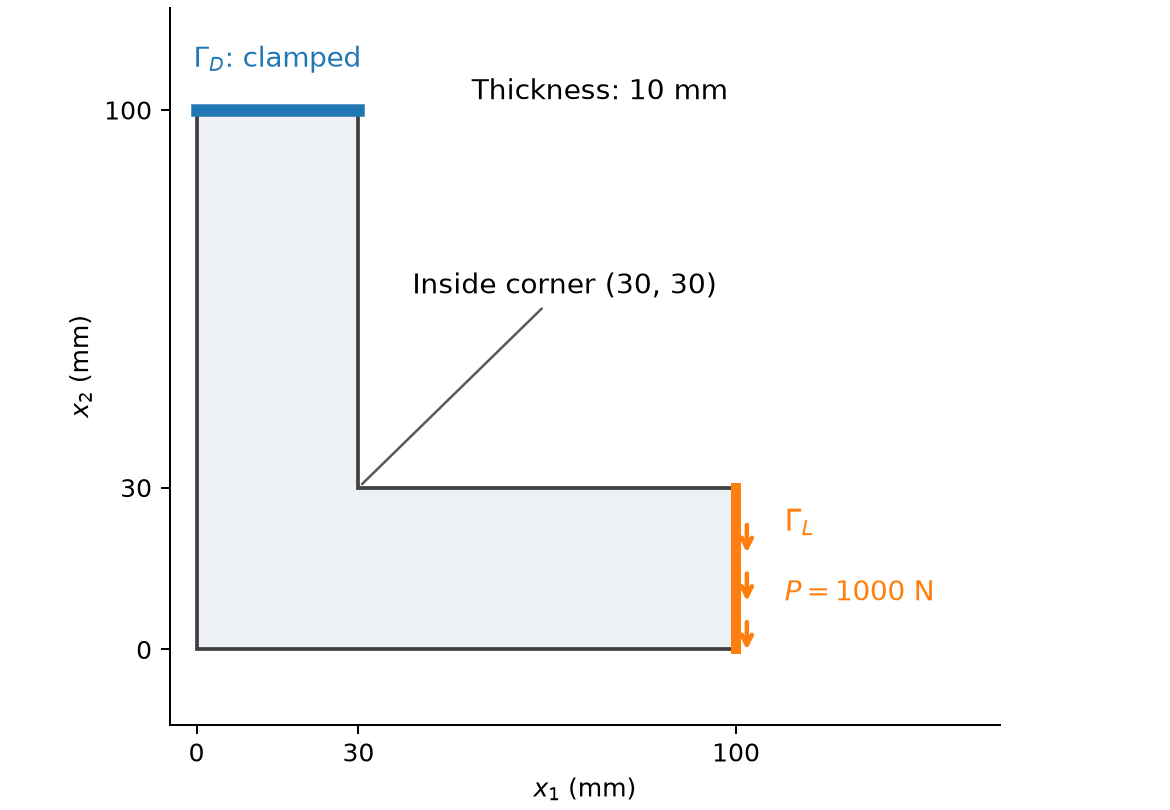

Use a **2D plane-stress model**, with thickness $t=10$ mm,
$E=70\,000$ MPa, $\nu=0.3$, yield strength $\sigma_Y=250$ MPa,
and total load $P=1000$ N.
Coordinates are in mm; stresses are in MPa (N/mm$^2$).
The domain and boundary conditions are
$$
\Omega=((0,100)\times(0,30))\cup((0,30)\times(0,100)),
\qquad \Gamma_D=\partial\Omega\cap\{x_2=100\},\quad
\Gamma_L=\partial\Omega\cap\{x_1=100\},
$$
$$
\begin{cases}
-\nabla\cdot\boldsymbol\sigma(\boldsymbol u)=\boldsymbol0 &\text{in }\Omega,\\
\boldsymbol u=\boldsymbol0 &\text{on }\Gamma_D,\\
\boldsymbol\sigma(\boldsymbol u)\boldsymbol n=\overline{\boldsymbol t}=(0,-P/(30t))^T &\text{on }\Gamma_L,\\
\boldsymbol\sigma(\boldsymbol u)\boldsymbol n=\boldsymbol0 &\text{on the other edges}.
\end{cases}
$$
Here $\boldsymbol n$ is the outward unit normal. There is no body force.
For plane stress, the in-plane constitutive law is
$$
\boldsymbol\varepsilon(\boldsymbol u)=\operatorname{sym}\nabla\boldsymbol u,
\quad \boldsymbol\sigma(\boldsymbol u)=2\mu\boldsymbol\varepsilon(\boldsymbol u)
+\lambda_{\rm ps}\operatorname{tr}(\boldsymbol\varepsilon(\boldsymbol u))\boldsymbol I_2,
\quad \mu=\frac{E}{2(1+\nu)},\quad \lambda_{\rm ps}=\frac{E\nu}{1-\nu^2}.
$$
Use the finite element space
$\mathcal V_{h,0}=\{\boldsymbol v_h\in H^1(\Omega;\mathbb R^2):
\boldsymbol v_h|_{\mathcal K_e}\in[P_1(\mathcal K_e)]^2,
\ \boldsymbol v_h=\boldsymbol0\text{ on }\Gamma_D\}$.
The supplied solver implements
$$
\underbrace{t\int_\Omega\boldsymbol\sigma(\boldsymbol u_h):
\boldsymbol\varepsilon(\boldsymbol v_h)\,dx}_{a_{\rm el}(\boldsymbol u_h,\boldsymbol v_h)}
=\underbrace{t\int_{\Gamma_L}\overline{\boldsymbol t}\cdot\boldsymbol v_h\,ds}_{\ell_{\rm el}(\boldsymbol v_h)}
\quad\forall\boldsymbol v_h\in\mathcal V_{h,0}.
$$
Record the average downward end deflection
$\delta_h=-\frac1{30}\int_{\Gamma_L}u_{h,2}\,ds$ in mm.

## Setup and submission
Use the **Python (Finite Elements)** kernel on one MPI process.
Complete the TODO cells. Restart the kernel, run all cells, and submit
`lastname_assignment05.ipynb` with outputs and answers.

Resources: [environment setup](https://github.com/CEADpx/finite-element-methods/blob/main/environment/README.md),
[marking](https://ceadpx.github.io/finite-element-methods/chapters/08-aposteriori-adaptivity.html#sec-c8-marking),
[DG0 assembly and refinement](https://ceadpx.github.io/finite-element-methods/chapters/08-aposteriori-adaptivity.html#sec-c8-fenicsx),
[lecture notebook](https://github.com/CEADpx/finite-element-methods/blob/main/notebooks/adaptivity/residual_adaptivity.ipynb),
[corner-stress example](https://ceadpx.github.io/finite-element-methods/chapters/07-apriori-error.html#sec-c7-corner-elasticity).

In [ ]:
import os
import sys

# On macOS, use the system compiler for FEniCSx's generated code.
if sys.platform == "darwin":
    os.environ.setdefault("CC", "/usr/bin/clang")
    os.environ.setdefault("LDSHARED", "/usr/bin/clang -bundle -undefined dynamic_lookup")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ufl
from mpi4py import MPI
from petsc4py import PETSc
from dolfinx import fem, mesh
from dolfinx.fem.petsc import LinearProblem

E, nu, thickness, P = 70000.0, 0.3, 10.0, 1000.0
yield_strength = 250.0  # MPa
tolerance = 0.01  # 1% relative change in end deflection
mu = E / (2 * (1 + nu))
lambda_ps = E * nu / (1 - nu**2)
traction = ufl.as_vector((0.0, -P / (30 * thickness)))

def strain(u):
    return ufl.sym(ufl.grad(u))

def stress(u):
    return 2 * mu * strain(u) + lambda_ps * ufl.tr(strain(u)) * ufl.Identity(2)

### Supplied mesh and boundary labels
The initial square grid has edges at 30 mm, so removing its upper-right
part gives the bracket exactly. Boundary tag 1 is loaded, tag 2 is clamped
and tag 0 is traction-free. These labels are rebuilt on each refined mesh.

In [ ]:
def make_bracket():
    square = mesh.create_rectangle(
        MPI.COMM_SELF, [[0.0, 0.0], [100.0, 100.0]], [10, 10],
        cell_type=mesh.CellType.triangle,
    )
    elements = np.arange(square.topology.index_map(2).size_local, dtype=np.int32)
    centers = mesh.compute_midpoints(square, 2, elements)
    keep = elements[(centers[:, 0] < 30) | (centers[:, 1] < 30)]
    domain, _, _, _ = mesh.create_submesh(square, 2, keep)
    return domain

def boundary_data(domain):
    domain.topology.create_connectivity(1, 2)
    exterior = mesh.exterior_facet_indices(domain.topology)
    fixed = mesh.locate_entities_boundary(domain, 1, lambda x: np.isclose(x[1], 100))
    loaded = mesh.locate_entities_boundary(domain, 1, lambda x: np.isclose(x[0], 100))
    labels = np.zeros(len(exterior), dtype=np.int32)
    labels[np.isin(exterior, loaded)] = 1
    labels[np.isin(exterior, fixed)] = 2
    tags = mesh.meshtags(domain, 1, exterior, labels)
    ds = ufl.Measure("ds", domain=domain, subdomain_data=tags)
    return fixed, ds

### Supplied elasticity solver
`solve_bracket(domain)` returns the displacement and $\delta_h$.
`LinearProblem` assembles and solves the equations with a direct LU solver;
`preonly` and `lu` select this solve, and `mumps` selects its factorization
package, already included in the course environment.

In [ ]:
def solve_bracket(domain):
    V = fem.functionspace(domain, ("Lagrange", 1, (2,)))
    fixed, ds = boundary_data(domain)
    dofs = fem.locate_dofs_topological(V, 1, fixed)
    bc = fem.dirichletbc(np.zeros(2, dtype=PETSc.ScalarType), dofs, V)

    u, v = ufl.TrialFunction(V), ufl.TestFunction(V)
    a = thickness * ufl.inner(stress(u), strain(v)) * ufl.dx
    ell = thickness * ufl.dot(traction, v) * ds(1)
    problem = LinearProblem(
        a, ell, bcs=[bc], petsc_options_prefix="bracket_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu",
                       "pc_factor_mat_solver_type": "mumps"},
    )
    u_h = problem.solve()
    delta = -fem.assemble_scalar(fem.form(u_h[1] * ds(1))) / 30
    return u_h, delta

### Supplied residual indicators
The stress is constant inside each $P_1$ triangle, so its element residual
is zero here. The indicator contains interior and Neumann edge residuals:
$$
\boldsymbol j_F=\begin{cases}
-(\boldsymbol\sigma_h^+\boldsymbol n^++\boldsymbol\sigma_h^-\boldsymbol n^-)
& F\text{ interior},\\
\overline{\boldsymbol t}-\boldsymbol\sigma_h\boldsymbol n
& F\subset\Gamma_N,
\end{cases}\qquad
\eta_e^2=\frac{t}{E}\left[
\frac12\sum_{F\subset\partial\mathcal K_e\cap\Omega}h_F\int_F\boldsymbol j_F\cdot\boldsymbol j_F\,ds
+\sum_{F\subset\partial\mathcal K_e\cap\Gamma_N}h_F\int_F\boldsymbol j_F\cdot\boldsymbol j_F\,ds\right].
$$
Here $h_F$ is edge length; $\Gamma_N$ includes the loaded and traction-free
edges, but not the clamp. Use $\overline{\boldsymbol t}=\boldsymbol0$ on free
edges. The global estimator is $\eta=(\sum_e\eta_e^2)^{1/2}$.

#### How DG0 produces one entry per element
DG0 is the space $W_h$ of functions that are constant on each triangle,
independently of neighbouring triangles. Its basis functions are
$$
\psi_e|_{\mathcal K_{e'}}=
\begin{cases}1,&e'=e,\\0,&e'\ne e.\end{cases}
$$
Let $\mathcal F_h^{\rm int}$ and $\mathcal F_h^N$ denote the interior and
Neumann edges. Write the weighted contribution of one edge as
$c_F=\frac{t}{E}h_F\int_F\boldsymbol j_F\cdot\boldsymbol j_F\,ds$.
For $z_h\in W_h$, define the linear form
$$
B(z_h)=\frac12\sum_{F\in\mathcal F_h^{\rm int}}
 c_F(z_h^++z_h^-)
 +\sum_{F\in\mathcal F_h^N}c_F\,z_h|_F.
$$
The traces $z_h^+$ and $z_h^-$ are constant values from the two neighbouring
elements. To compute the entry for element $e$, substitute $z_h=\psi_e$.
On each interior edge of that element, one trace is 1 and the other is 0,
so $(\psi_e^++\psi_e^-)/2=1/2$. On its Neumann edges, $\psi_e=1$.
On edges not belonging to the element, both contributions vanish. Hence
$$
B(\psi_e)=
\frac12\sum_{\substack{F\subset\partial\mathcal K_e\\F\in\mathcal F_h^{\rm int}}}c_F
+\sum_{\substack{F\subset\partial\mathcal K_e\\F\in\mathcal F_h^N}}c_F
=\eta_e^2.
$$

In the code, `z` represents $z_h$; `assemble_vector` evaluates $B$ on every
DG0 basis function. `Q.dofmap.cell_dofs(e)[0]` locates $B(\psi_e)$ in that
vector, and the final loop puts these entries into element order.

`jump(sigma, n)` sums the two outward tractions. `dS` integrates over
interior edges; `ds(0)` and `ds(1)` integrate over traction-free and loaded
edges. `avg(h)` gives the shared edge length, and `(z("+")+z("-"))/2`
implements the half contribution derived above. DG0 is used only to
assemble the indicators; the displacement still uses continuous $P_1$ elements.

In [ ]:
def indicators(domain, u_h):
    Q = fem.functionspace(domain, ("DG", 0))
    z = ufl.TestFunction(Q)
    n = ufl.FacetNormal(domain)
    h = ufl.FacetArea(domain)  # In 2D, facet measure is edge length.
    sigma = stress(u_h)
    jump = -ufl.jump(sigma, n)
    interior = ufl.avg(h) * ufl.dot(jump, jump) * (z("+") + z("-")) / 2 * ufl.dS

    _, ds = boundary_data(domain)
    free = -ufl.dot(sigma, n)
    loaded = traction - ufl.dot(sigma, n)
    boundary = h * ufl.dot(free, free) * z * ds(0)
    boundary += h * ufl.dot(loaded, loaded) * z * ds(1)
    vector = fem.assemble_vector(fem.form(thickness / E * (interior + boundary)))

    count = domain.topology.index_map(2).size_local
    squared = np.zeros(count)
    for e in range(count):
        dof = Q.dofmap.cell_dofs(e)[0]
        squared[e] = vector.array[dof].real
    return np.maximum(squared, 0)

### Supplied corner-stress measurement and plotting
For plane stress,
$\sigma_{\rm vm}=\sqrt{\sigma_{11}^2-\sigma_{11}\sigma_{22}+\sigma_{22}^2+3\sigma_{12}^2}$.
Use the following region on every mesh:
$$
\Omega_c=\Omega\cap\big((20,40)\times(20,40)\big).
$$
This L-shaped region surrounds the inside corner and has area 300 mm$^2$.
Its edges align with the initial mesh, so it is a union of complete elements
on every refined mesh. The dashed green outline in the mesh plots identifies it.
`corner_stress` returns the peak stress and the area-weighted average
$$
\overline\sigma_{\rm vm,c}
=\frac{\int_{\Omega_c}\sigma_{\rm vm}\,dx}{|\Omega_c|}
=\frac{\sum_{\mathcal K_e\subset\Omega_c}A_e\sigma_{{\rm vm},e}}
       {\sum_{\mathcal K_e\subset\Omega_c}A_e},
\qquad A_e=\int_\Omega\psi_e\,dx.
$$
The stress is constant on each $P_1$ triangle. The routine uses DG0 to
obtain its value and the element area $A_e$, then computes this weighted sum.

For the final mesh, calculate the factor of safety using the average von Mises stress:
$$
n_{\rm avg}=\frac{\sigma_Y}{\overline\sigma_{\rm vm,c}},\qquad
\sigma_Y=250\ \mathrm{MPa}.
$$
The required factor of safety is 2.

`plot_mesh` shows a mesh, optional element values and marked elements
outlined in blue. Python element indices start at zero.

In [ ]:
def corner_stress(domain, u_h):
    sigma = stress(u_h)
    vm = ufl.sqrt(sigma[0, 0]**2 - sigma[0, 0] * sigma[1, 1]
                  + sigma[1, 1]**2 + 3 * sigma[0, 1]**2)
    Q = fem.functionspace(domain, ("DG", 0))
    field = fem.Function(Q)
    field.interpolate(fem.Expression(vm, Q.element.interpolation_points))
    area_vector = fem.assemble_vector(fem.form(ufl.TestFunction(Q) * ufl.dx))
    elements = np.arange(domain.topology.index_map(2).size_local, dtype=np.int32)
    centers = mesh.compute_midpoints(domain, 2, elements)
    values = np.zeros(len(elements))
    areas = np.zeros(len(elements))
    for e in elements:
        dof = Q.dofmap.cell_dofs(e)[0]
        values[e] = field.x.array[dof]
        areas[e] = area_vector.array[dof].real
    in_region = ((centers[:, 0] > 20) & (centers[:, 0] < 40)
                 & (centers[:, 1] > 20) & (centers[:, 1] < 40))
    peak = values[in_region].max()
    average = np.sum(areas[in_region] * values[in_region]) / areas[in_region].sum()
    return peak, average

def plot_mesh(domain, values=None, marked=None, title="", label=""):
    x = domain.geometry.x
    triangles = domain.geometry.dofmaps[0]
    fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
    if values is not None:
        image = ax.tripcolor(x[:, 0], x[:, 1], triangles, facecolors=values, cmap="magma")
        fig.colorbar(image, ax=ax, shrink=0.8, label=label)
    ax.triplot(x[:, 0], x[:, 1], triangles, color="0.45", lw=0.3)
    if marked is not None:
        for e in marked:
            nodes = np.append(triangles[e], triangles[e, 0])
            ax.plot(x[nodes, 0], x[nodes, 1], color="tab:blue", lw=0.9)
    ax.plot([20, 40, 40, 30, 30, 20, 20], [20, 20, 30, 30, 40, 40, 20],
            "--", color="tab:green", lw=1.2, label="Stress averaging region")
    ax.legend(loc="upper right", fontsize=8)
    ax.set(aspect="equal", xlabel="$x_1$ (mm)", ylabel="$x_2$ (mm)", title=title)
    plt.show()

### Initial solution
Run this calculation once to check your setup. The table counts all
displacement DOFs, including prescribed ones. The figure shows the initial mesh.

In [ ]:
initial_mesh = make_bracket()
u_initial, delta_initial = solve_bracket(initial_mesh)
initial_squared = indicators(initial_mesh, u_initial)
display(pd.DataFrame({"elements": [len(initial_squared)],
                      "DOFs": [u_initial.x.array.size], "delta_mm": [delta_initial]}))
plot_mesh(initial_mesh, title="Initial mesh")

## Task 1. Marking (25 marks)
1. Implement `mark_elements(squared, theta=0.5)`. Build the marked set $\mathcal M$
   by adding elements in decreasing order of $\eta_e^2$. Stop as soon as
   $$\sum_{e\in\mathcal M}\eta_e^2\ge\theta\sum_e\eta_e^2.$$
   Return their indices as a NumPy array with `dtype=np.int32`.
2. Apply your function to the initial-mesh indicators (`initial_squared`).
   Print the number of marked triangles and plot them on the initial mesh:
   ```python
   plot_mesh(initial_mesh, np.sqrt(initial_squared), marked)
   ```
   Here `marked` is the array of indices returned by your function.


In [ ]:
def mark_elements(squared, theta=0.5):
    # TODO: implement the marking criterion in Task 1.
    raise NotImplementedError

# TODO: mark the initial mesh, print the marked count, and plot the selection.

## Task 2. Adaptive refinement (45 marks)
1. Starting at cycle 0 on `initial_mesh`, implement **solve → estimate → mark → refine**
   with $\theta=0.5$.
2. Let $\delta_m$ be the end deflection from cycle $m$. From cycle 1 onward, compute
   $$d_m=\frac{|\delta_m-\delta_{m-1}|}{|\delta_m|}.$$
   Stop when $d_m\le0.01$ or after 10 solves, whichever occurs first.
3. Tabulate cycle, displacement DOFs, $\delta_m$, $\eta$, peak and average
   corner stresses, and $100d_m$ (%). Leave the first change entry blank.
   State whether the tolerance or solve limit stopped refinement.
4. For refinements at cycles 0, 2 and 5, plot the current indicators $\eta_e$
   with marked triangles outlined, followed by the mesh after refinement.

Use these calls for the refinement step:
```python
domain.topology.create_entities(1)
edges = mesh.compute_incident_entities(domain.topology, marked, 2, 1)
domain, _, _ = mesh.refine(domain, edges)
```
Dimensions 2 and 1 denote triangles and edges. FEniCSx maintains conformity.
Solve again on the new mesh; do not refine after the stopping condition is met.


In [ ]:
domain = initial_mesh
adaptive_rows = []
# TODO: write the adaptive loop and create adaptive_table with pd.DataFrame.
# Plot the indicator/marked mesh before replacing domain by its refinement.

## Task 3. Uniform refinement and factor of safety (30 marks)
1. Compute a uniform-refinement study from `initial_mesh`, using the same
   stopping tolerance and table quantities as Task 2, but at most 6 solves.
   Between solves, use
   ```python
   domain.topology.create_entities(1)
   domain, _, _ = mesh.refine(domain)
   ```
2. Compare the studies in three plots against DOFs: deflection, estimator
   and average corner stress. Use logarithmic DOF axes and a logarithmic
   vertical axis for the estimator.
3. For the last solved mesh in each study, tabulate DOFs, deflection, average and peak corner
   stresses, and $n_{\rm avg}$. State whether $n_{\rm avg}\ge2$.

Briefly answer:

- Which study meets the deflection-change tolerance with fewer DOFs, and where
  does adaptive refinement concentrate?
- Compare the average and peak stresses with $\sigma_Y$. Does $n_{\rm avg}\ge2$
  rule out local yielding? What would you change about the ideal sharp corner
  before assessing local stress in a real bracket?
- Does a change of at most 1% between successive deflections mean the computed
  deflection is within 1% of the exact deflection? Does it guarantee convergence
  of $n_{\rm avg}$?


In [ ]:
domain = initial_mesh
uniform_rows = []
# TODO: write the uniform loop and create uniform_table.

In [ ]:
# TODO: plot both studies and report the final-mesh stress and factor-of-safety comparison.

**Your answers to Task 3:**